In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# BLOQUE 1: SAMPLE

ruta = "Homicidios_intencionales_2026.csv"

# Leer como texto para conservar códigos y ceros iniciales.
df = pd.read_csv(
    ruta,
    sep=";",
    encoding="utf-8-sig",
    dtype="string",
    low_memory=False
)

# Normalizar encabezados.
df.columns = df.columns.str.strip()

if df.columns.duplicated().any():
    duplicadas = df.columns[df.columns.duplicated()].tolist()
    raise ValueError(f"Existen nombres de columnas duplicados: {duplicadas}")

# Eliminar espacios exteriores y convertir cadenas vacías en faltantes.
filas_leidas = len(df)

for col in df.columns:
    df[col] = df[col].str.strip()

df = df.replace(r"^\s*$", pd.NA, regex=True)
df = df.dropna(how="all").reset_index(drop=True)

# Conservar los nombres originales antes de crear variables auxiliares.
columnas_originales = df.columns.tolist()

# Comprobar columnas necesarias para este bloque.
columnas_requeridas = [
    "coordenada_x",
    "coordenada_y",
    "fecha_infraccion",
    "subzona",
    "distrito",
    "circuito",
    "subcircuito"
]

faltantes = [
    col for col in columnas_requeridas
    if col not in df.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas requeridas: {faltantes}\n"
        f"Columnas disponibles: {df.columns.tolist()}"
    )

# Convertir coordenadas sin sobrescribir los valores originales.
# Se presupone X = longitud, Y = latitud, expresadas en grados.
for col in ["coordenada_x", "coordenada_y"]:
    texto = df[col].str.replace(",", ".", regex=False)

    df[f"{col}_num"] = pd.to_numeric(
        texto,
        errors="coerce"
    )

# Bandera de control rectangular para el mapa continental.
# No comprueba pertenencia exacta al territorio de Ecuador.
df["coord_valida"] = (
    df["coordenada_x_num"].between(-81.5, -75.0)
    & df["coordenada_y_num"].between(-5.2, 1.6)
).fillna(False).astype(bool)

# Preparar fechas para diagnosticar periodo y errores de conversión.
# Ajustar el formato si el archivo no utiliza día/mes/año.
df["fecha_infraccion_dt"] = pd.to_datetime(
    df["fecha_infraccion"],
    dayfirst=True,
    errors="coerce"
)

# Diagnóstico de registros y calidad.
n_registros = len(df)
n_coord_validas = int(df["coord_valida"].sum())

pct_coord_validas = (
    100 * n_coord_validas / n_registros
    if n_registros > 0 else 0.0
)

coord_no_numericas = (
    df[["coordenada_x_num", "coordenada_y_num"]]
    .isna()
    .any(axis=1)
)

coord_fuera_rango = (
    ~coord_no_numericas & ~df["coord_valida"]
)

fecha_no_interpretable = (
    df["fecha_infraccion"].notna()
    & df["fecha_infraccion_dt"].isna()
)

duplicados_exactos = df.duplicated(
    subset=columnas_originales
).sum()

print("=== DIAGNÓSTICO INICIAL ===")
print(f"Filas leídas por pandas: {filas_leidas:,}")
print(
    f"Filas completamente vacías eliminadas: "
    f"{filas_leidas - n_registros:,}"
)
print(f"Registros conservados: {n_registros:,}")
print(
    f"Duplicados exactos potenciales: {duplicados_exactos:,} "
    "(no eliminados)"
)

print("\n=== COORDENADAS ===")
print(
    f"Registros dentro del rango de control: "
    f"{n_coord_validas:,} ({pct_coord_validas:.2f}%)"
)
print(
    f"Registros con alguna coordenada ausente o no interpretable: "
    f"{coord_no_numericas.sum():,}"
)
print(
    f"Registros con coordenadas numéricas fuera del rango: "
    f"{coord_fuera_rango.sum():,}"
)

print("\n=== FECHAS ===")
print(
    f"Registros sin fecha original: "
    f"{df['fecha_infraccion'].isna().sum():,}"
)
print(
    f"Fechas presentes no interpretables: "
    f"{fecha_no_interpretable.sum():,}"
)

fechas_validas = df["fecha_infraccion_dt"].dropna()

if not fechas_validas.empty:
    print(
        f"Periodo observado: "
        f"{fechas_validas.min():%d/%m/%Y} a "
        f"{fechas_validas.max():%d/%m/%Y}"
    )
    print("Registros por año:")
    print(
        fechas_validas.dt.year
        .value_counts()
        .sort_index()
        .to_string()
    )
else:
    print("No se pudieron interpretar fechas.")

print("\n=== COBERTURA TERRITORIAL POR NOMBRE ===")
for col in ["subzona", "distrito", "circuito", "subcircuito"]:
    print(
        f"{col}: {df[col].nunique():,} nombres distintos | "
        f"faltantes: {df[col].isna().sum():,}"
    )

# Base exclusiva para el mapa; df conserva todos los registros.
df_geo = df.loc[df["coord_valida"]].copy()

=== DIAGNÓSTICO INICIAL ===
Filas leídas por pandas: 1,008,753
Filas completamente vacías eliminadas: 1,001,864
Registros conservados: 6,889
Duplicados exactos potenciales: 54 (no eliminados)

=== COORDENADAS ===
Registros dentro del rango de control: 6,715 (97.47%)
Registros con alguna coordenada ausente o no interpretable: 174
Registros con coordenadas numéricas fuera del rango: 0

=== FECHAS ===
Registros sin fecha original: 0
Fechas presentes no interpretables: 0
Periodo observado: 01/01/2026 a 31/10/2026
Registros por año:
fecha_infraccion_dt
2026    6889

=== COBERTURA TERRITORIAL POR NOMBRE ===
subzona: 25 nombres distintos | faltantes: 0
distrito: 122 nombres distintos | faltantes: 0
circuito: 636 nombres distintos | faltantes: 0
subcircuito: 1,016 nombres distintos | faltantes: 0


Identificador de subcircuito utilizado: codigo_subcircuito
Nombres de subcircuito asociados a más de un código: 46


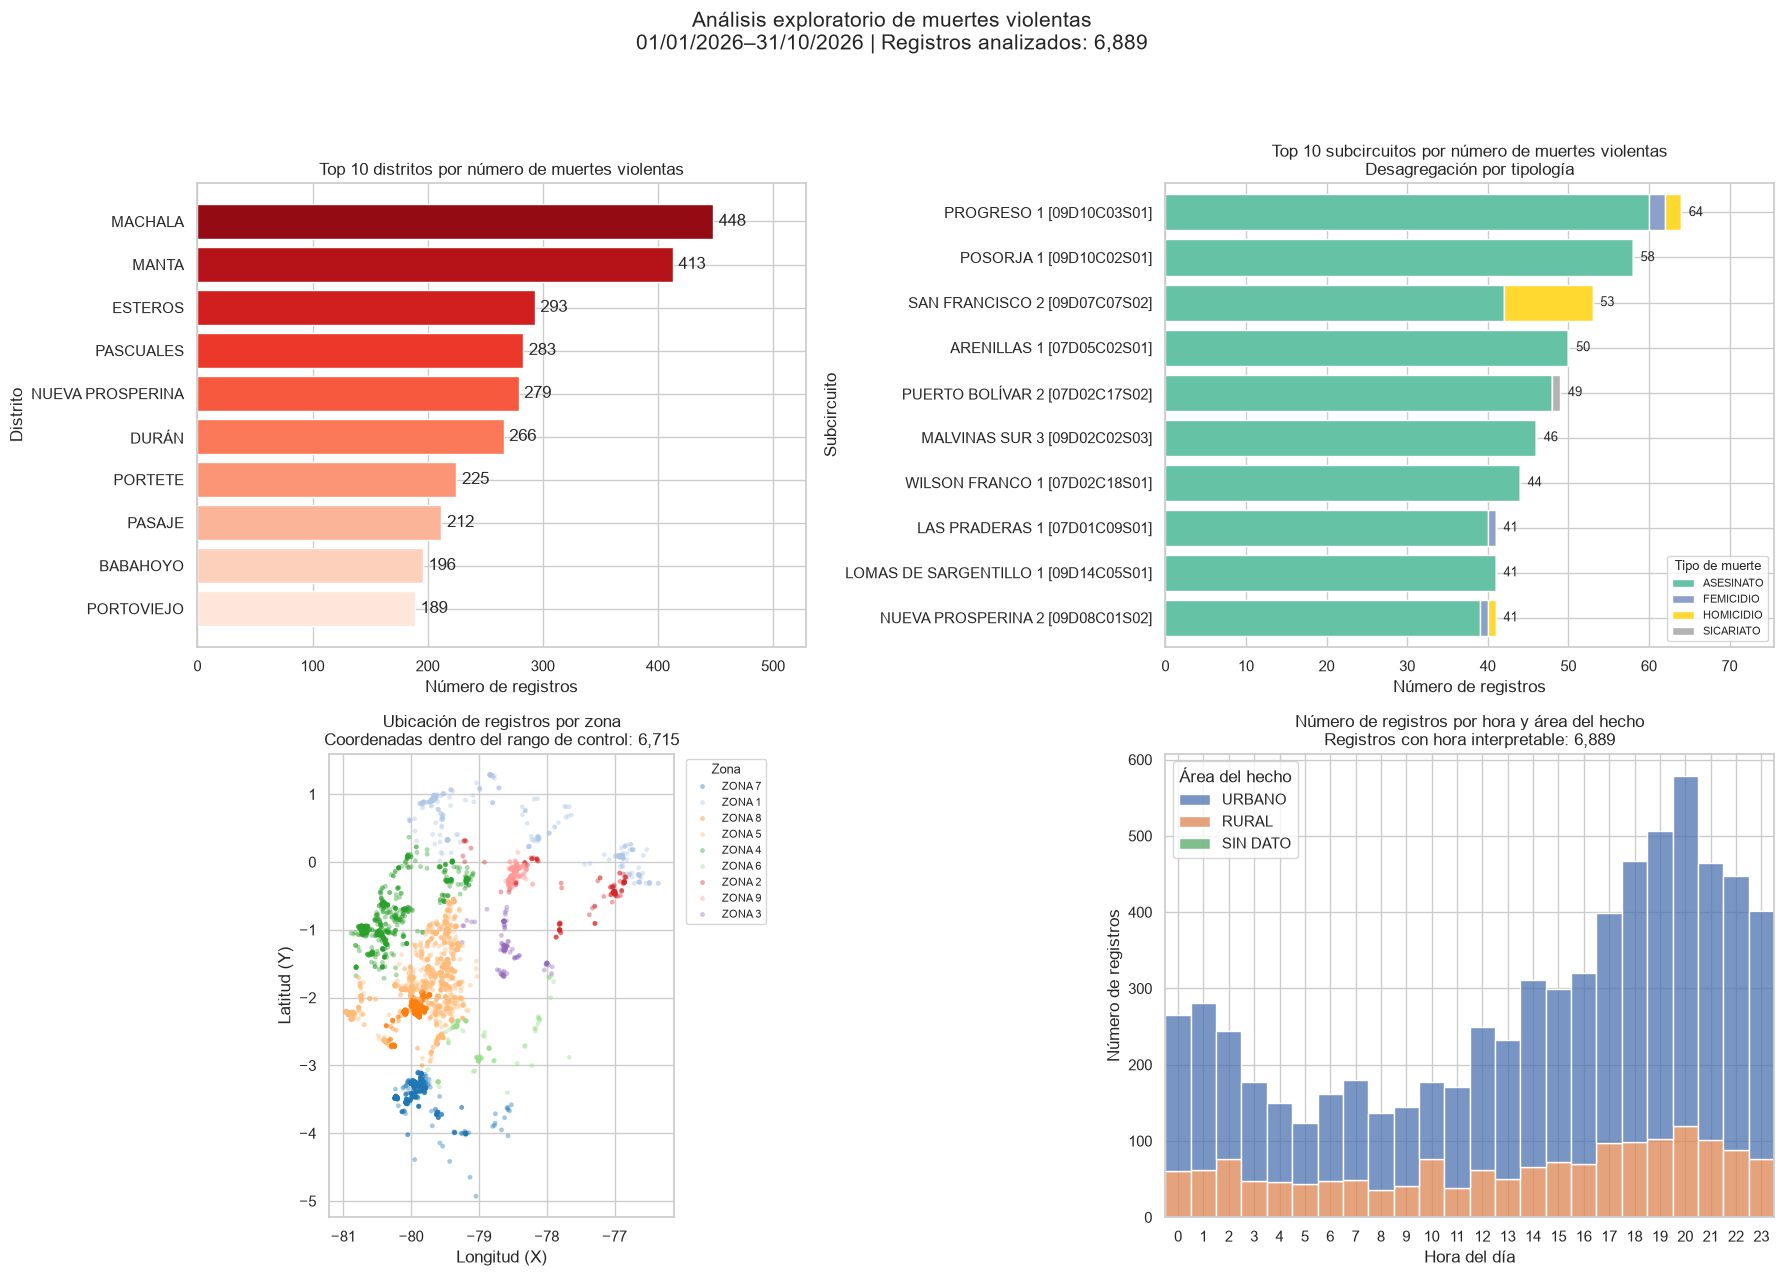


=== CONCENTRACIÓN TERRITORIAL ===
Subcircuitos identificados con registros: 1,071
Registros sin identificador territorial utilizable: 0

Los 107 subcircuitos con más registros (9.99% de los observados) concentran:
- 2,653 registros.
- 38.51% de todos los registros.
- 38.51% de los registros con subcircuito identificado.

Primeros 10 subcircuitos de la tabla de concentración:


,subcircuito_id,n_registros,porcentaje_total,porcentaje_acumulado_identificados
0,09D10C03S01,64,0.93,0.93
1,09D10C02S01,58,0.84,1.77
2,09D07C07S02,53,0.77,2.54
3,07D05C02S01,50,0.73,3.27
4,07D02C17S02,49,0.71,3.98
5,09D02C02S03,46,0.67,4.65
6,07D02C18S01,44,0.64,5.28
7,07D01C09S01,41,0.6,5.88
8,09D14C05S01,41,0.6,6.47
9,09D08C01S02,41,0.6,7.07



=== COBERTURA DEL ANÁLISIS HORARIO ===
Registros con hora interpretable: 6,889
Registros sin hora interpretable: 0


In [ ]:
# BLOQUE 2: EXPLORE
# Rankings, distribución espacial, horarios
# y concentración territorial

columnas_requeridas = [
    "distrito", "subcircuito", "tipo_muerte",
    "zona", "area_hecho", "hora_infraccion",
    "coordenada_x_num", "coordenada_y_num", "coord_valida"
]

faltantes = [
    col for col in columnas_requeridas
    if col not in df.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas requeridas: {faltantes}")

if df.empty:
    raise ValueError("La base no contiene registros para analizar.")


# 1. Preparar identificadores y categorías para este análisis.
# No se modifican las columnas originales.
categorias_desconocidas = {
    "", "SIN DATO", "SIN DATOS", "NO REGISTRA",
    "NO REGISTRADO", "NO DISPONIBLE", "DESCONOCIDO",
    "S/D", "N/A"
}

def limpiar_categoria(serie):
    limpia = (
        serie.astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
        .str.upper()
    )
    return limpia.mask(limpia.isin(categorias_desconocidas))


df["distrito_eda"] = limpiar_categoria(df["distrito"])
df["subcircuito_nombre_eda"] = limpiar_categoria(df["subcircuito"])

# Buscar una columna de código de subcircuito.
candidatas_codigo = [
    "codigo_subcircuito",
    "código_subcircuito",
    "cod_subcircuito",
    "codigo subcircuito",
    "código subcircuito"
]

col_codigo_sub = next(
    (col for col in candidatas_codigo if col in df.columns),
    None
)

if col_codigo_sub is not None:
    df["subcircuito_id_eda"] = limpiar_categoria(df[col_codigo_sub])
    print(f"Identificador de subcircuito utilizado: {col_codigo_sub}")

    # Revisar nombres asociados a más de un código.
    nombres_multicodigo = (
        df.dropna(
            subset=["subcircuito_nombre_eda", "subcircuito_id_eda"]
        )
        .groupby("subcircuito_nombre_eda")["subcircuito_id_eda"]
        .nunique()
    )

    n_nombres_repetidos = int((nombres_multicodigo > 1).sum())
    print(
        "Nombres de subcircuito asociados a más de un código: "
        f"{n_nombres_repetidos}"
    )
else:
    df["subcircuito_id_eda"] = df["subcircuito_nombre_eda"]
    print(
        "ADVERTENCIA: no se encontró código de subcircuito. "
        "Se agrupará por nombre; verifica que sea único."
    )

df["tipo_muerte_eda"] = (
    limpiar_categoria(df["tipo_muerte"])
    .fillna("SIN DATO")
)

df["zona_eda"] = (
    limpiar_categoria(df["zona"])
    .fillna("SIN DATO")
)

df["area_hecho_eda"] = (
    limpiar_categoria(df["area_hecho"])
    .replace({"SIN_DATO": "SIN DATO"})
    .fillna("SIN DATO")
)


# 2. Extraer hora y revisar cobertura temporal.
df["hora_num"] = pd.to_datetime(
    df["hora_infraccion"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour

n_horas_validas = int(df["hora_num"].notna().sum())

fechas_validas = df["fecha_infraccion_dt"].dropna()

periodo = (
    f"{fechas_validas.min():%d/%m/%Y}–"
    f"{fechas_validas.max():%d/%m/%Y}"
    if not fechas_validas.empty
    else "Periodo no determinado"
)

# 3. Tablas para los rankings.
top_distritos = df["distrito_eda"].value_counts().head(10)

conteo_sub = df["subcircuito_id_eda"].value_counts()
top_sub = conteo_sub.head(10).index

# Etiquetas: nombre + código cuando se dispone de ambos.
tabla_nombres = (
    df.dropna(
        subset=["subcircuito_id_eda", "subcircuito_nombre_eda"]
    )
    .groupby("subcircuito_id_eda")["subcircuito_nombre_eda"]
    .agg(lambda s: s.value_counts().index[0])
)

etiquetas_sub = {}

for identificador in top_sub:
    nombre = tabla_nombres.get(identificador, identificador)

    etiquetas_sub[identificador] = (
        f"{nombre} [{identificador}]"
        if col_codigo_sub is not None
        else str(nombre)
    )

df_top_sub = df.loc[
    df["subcircuito_id_eda"].isin(top_sub)
].copy()

tabla_tipologias = pd.crosstab(
    df_top_sub["subcircuito_id_eda"],
    df_top_sub["tipo_muerte_eda"]
).reindex(index=top_sub, fill_value=0)

tabla_tipologias = tabla_tipologias.rename(index=etiquetas_sub)

# 4. Panel exploratorio.
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(18, 13))

fig.suptitle(
    f"Análisis exploratorio de muertes violentas\n"
    f"{periodo} | Registros analizados: {len(df):,}",
    fontsize=15
)

# 4.1. Top 10 distritos por número de registros.
if not top_distritos.empty:
    colores = sns.color_palette("Reds_r", n_colors=len(top_distritos))

    barras = axes[0, 0].barh(
        top_distritos.index.astype(str),
        top_distritos.values,
        color=colores
    )

    axes[0, 0].invert_yaxis()
    axes[0, 0].bar_label(barras, padding=4, fmt="%.0f")
    axes[0, 0].set_xlim(0, top_distritos.max() * 1.18)
else:
    axes[0, 0].text(
        0.5, 0.5, "Sin distritos identificados",
        ha="center", va="center",
        transform=axes[0, 0].transAxes
    )

axes[0, 0].set_title(
    "Top 10 distritos por número de muertes violentas"
)
axes[0, 0].set_xlabel("Número de registros")
axes[0, 0].set_ylabel("Distrito")


# 4.2. Top 10 subcircuitos, desagregados por tipología.
if not tabla_tipologias.empty:
    tabla_tipologias.plot(
        kind="barh",
        stacked=True,
        ax=axes[0, 1],
        colormap="Set2",
        width=0.8
    )

    axes[0, 1].invert_yaxis()

    totales = tabla_tipologias.sum(axis=1)

    for posicion, total in enumerate(totales):
        axes[0, 1].text(
            total + totales.max() * 0.015,
            posicion,
            str(int(total)),
            va="center",
            fontsize=9
        )

    axes[0, 1].set_xlim(0, totales.max() * 1.18)
    axes[0, 1].legend(
        title="Tipo de muerte",
        fontsize=8,
        title_fontsize=9
    )
else:
    axes[0, 1].text(
        0.5, 0.5, "Sin subcircuitos identificados",
        ha="center", va="center",
        transform=axes[0, 1].transAxes
    )

axes[0, 1].set_title(
    "Top 10 subcircuitos por número de muertes violentas\n"
    "Desagregación por tipología"
)
axes[0, 1].set_xlabel("Número de registros")
axes[0, 1].set_ylabel("Subcircuito")

# 4.3. Distribución de puntos por zona.
df_geo = df.loc[df["coord_valida"]].copy()

if not df_geo.empty:
    sns.scatterplot(
        data=df_geo,
        x="coordenada_x_num",
        y="coordenada_y_num",
        hue="zona_eda",
        palette="tab20",
        alpha=0.4,
        s=12,
        linewidth=0,
        ax=axes[1, 0]
    )

    axes[1, 0].legend(
        title="Zona",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
        title_fontsize=9
    )

    axes[1, 0].set_aspect("equal", adjustable="box")
else:
    axes[1, 0].text(
        0.5, 0.5, "Sin coordenadas dentro del rango de control",
        ha="center", va="center",
        transform=axes[1, 0].transAxes
    )

axes[1, 0].set_title(
    "Ubicación de registros por zona\n"
    f"Coordenadas dentro del rango de control: {len(df_geo):,}"
)
axes[1, 0].set_xlabel("Longitud (X)")
axes[1, 0].set_ylabel("Latitud (Y)")

# 4.4. Distribución horaria por área del hecho.
if n_horas_validas > 0:
    sns.histplot(
        data=df.loc[df["hora_num"].notna()],
        x="hora_num",
        hue="area_hecho_eda",
        bins=np.arange(-0.5, 24.5, 1),
        multiple="stack",
        ax=axes[1, 1]
    )

    leyenda = axes[1, 1].get_legend()
    if leyenda is not None:
        leyenda.set_title("Área del hecho")
else:
    axes[1, 1].text(
        0.5, 0.5, "Sin horas interpretables",
        ha="center", va="center",
        transform=axes[1, 1].transAxes
    )

axes[1, 1].set_xlim(-0.5, 23.5)
axes[1, 1].set_xticks(range(24))
axes[1, 1].set_title(
    "Número de registros por hora y área del hecho\n"
    f"Registros con hora interpretable: {n_horas_validas:,}"
)
axes[1, 1].set_xlabel("Hora del día")
axes[1, 1].set_ylabel("Número de registros")

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# 5. Concentración territorial: aproximadamente el 10% superior.
print("\n=== CONCENTRACIÓN TERRITORIAL ===")

n_sub = len(conteo_sub)
n_total = len(df)
n_identificados = int(conteo_sub.sum())

print(f"Subcircuitos identificados con registros: {n_sub:,}")
print(
    f"Registros sin identificador territorial utilizable: "
    f"{n_total - n_identificados:,}"
)

if n_sub > 0:
    # Mantiene el criterio original: redondeo hacia abajo.
    n_top = max(1, int(n_sub * 0.10))
    casos_top = int(conteo_sub.head(n_top).sum())

    pct_sub = 100 * n_top / n_sub
    pct_total = 100 * casos_top / n_total
    pct_identificados = 100 * casos_top / n_identificados

    print(
        f"\nLos {n_top:,} subcircuitos con más registros "
        f"({pct_sub:.2f}% de los observados) concentran:"
    )
    print(f"- {casos_top:,} registros.")
    print(f"- {pct_total:.2f}% de todos los registros.")
    print(
        f"- {pct_identificados:.2f}% de los registros "
        "con subcircuito identificado."
    )

    tabla_concentracion = (
        conteo_sub.rename("n_registros")
        .rename_axis("subcircuito_id")
        .reset_index()
    )

    tabla_concentracion["porcentaje_total"] = (
        100 * tabla_concentracion["n_registros"] / n_total
    )

    tabla_concentracion["porcentaje_acumulado_identificados"] = (
        100
        * tabla_concentracion["n_registros"].cumsum()
        / n_identificados
    )

    print("\nPrimeros 10 subcircuitos de la tabla de concentración:")
    display(tabla_concentracion.head(10).round(2))

else:
    tabla_concentracion = pd.DataFrame()
    print("No hay subcircuitos identificados para calcular concentración.")

print("\n=== COBERTURA DEL ANÁLISIS HORARIO ===")
print(f"Registros con hora interpretable: {n_horas_validas:,}")
print(
    f"Registros sin hora interpretable: "
    f"{len(df) - n_horas_validas:,}"
)

In [ ]:
# BLOQUE 3: MODIFY
# Target retrospectivo, variables y partición territorial

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Este target describe concentración en el periodo completo observado.
# No representa criticidad futura.

columnas_requeridas = [
    "subcircuito_id_eda",
    "edad",
    "medida_edad",
    "hora_infraccion",
    "fecha_infraccion_dt",
    "zona",
    "area_hecho",
    "tipo_lugar",
    "lugar",
    "tipo_muerte",
    "arma",
    "tipo_arma",
    "presun_motiva_observada",
    "probable_causa_motivada",
    "sexo",
    "etnia",
    "estado_civil",
    "nacionalidad"
]

faltantes = [
    col for col in columnas_requeridas
    if col not in df.columns
]

if faltantes:
    raise ValueError(
        f"Faltan columnas requeridas: {faltantes}\n"
        "Revisa sus nombres exactos en df.columns."
    )

# 1. Seleccionar registros con subcircuito identificable.
df_pred = (
    df.loc[df["subcircuito_id_eda"].notna()]
    .copy()
    .reset_index(drop=True)
)

if df_pred.empty:
    raise ValueError("No existen registros con subcircuito identificable.")

print("=== BASE PARA CLASIFICACIÓN RETROSPECTIVA ===")
print(f"Registros originales: {len(df):,}")
print(f"Registros incluidos: {len(df_pred):,}")
print(
    f"Registros excluidos por falta de identificador: "
    f"{len(df) - len(df_pred):,}"
)

# 2. Construir el target territorial retrospectivo.
conteo_sub = df_pred["subcircuito_id_eda"].value_counts()

umbral_critico = conteo_sub.quantile(0.85)
minimo_casos_criticos = int(np.ceil(umbral_critico))

resumen_sub = (
    conteo_sub.rename("n_registros")
    .rename_axis("subcircuito_id_eda")
    .to_frame()
)

resumen_sub["criticidad_alta"] = (
    resumen_sub["n_registros"] >= umbral_critico
).astype(int)

df_pred["criticidad_alta"] = (
    df_pred["subcircuito_id_eda"]
    .map(resumen_sub["criticidad_alta"])
    .astype(int)
)

print("\n=== DEFINICIÓN DEL TARGET ===")
print(f"Percentil 85 de los conteos: {umbral_critico:.4f}")
print(
    f"Alta concentración: al menos "
    f"{minimo_casos_criticos} registros en el periodo observado."
)
print(
    "El porcentaje de subcircuitos críticos puede superar el 15% "
    "por empates en el umbral."
)

def tabla_balance(serie):
    conteos = serie.value_counts().reindex([0, 1], fill_value=0)

    return pd.DataFrame({
        "cantidad": conteos,
        "porcentaje": 100 * conteos / conteos.sum()
    }).rename_axis("criticidad_alta")

print("\nBalance por subcircuitos:")
display(tabla_balance(resumen_sub["criticidad_alta"]).round(2))

print("\nBalance por registros:")
display(tabla_balance(df_pred["criticidad_alta"]).round(2))

if df_pred["criticidad_alta"].nunique() < 2:
    raise ValueError(
        "El criterio produce una sola clase. "
        "Revisa los conteos y el umbral."
    )

# 3. Preparar edad considerando la unidad de medida.
edad_original_num = pd.to_numeric(
    df_pred["edad"].str.replace(",", ".", regex=False),
    errors="coerce"
)

unidad_edad = (
    df_pred["medida_edad"]
    .astype("string")
    .str.strip()
    .str.upper()
    .str.replace("Ñ", "N", regex=False)
)

# Si la unidad está codificada numéricamente, completar este mapa
# SOLO después de consultar el diccionario de datos.
# Ejemplo de estructura: {"codigo_confirmado": "ANOS"}
mapa_unidad_edad = {}

unidad_edad = unidad_edad.replace(mapa_unidad_edad)

factores_edad = {
    "A": 1.0,
    "ANO": 1.0,
    "ANOS": 1.0,
    "ANIO": 1.0,
    "ANIOS": 1.0,
    "MES": 1 / 12,
    "MESES": 1 / 12,
    "DIA": 1 / 365.25,
    "DIAS": 1 / 365.25
}

factor_edad = unidad_edad.map(factores_edad)

df_pred["edad_num"] = (
    edad_original_num * factor_edad
).astype(float)

# Rango de control, no eliminación de registros.
edad_fuera_rango = (
    df_pred["edad_num"].notna()
    & ~df_pred["edad_num"].between(0, 120)
)

df_pred.loc[edad_fuera_rango, "edad_num"] = np.nan

unidades_no_reconocidas = (
    unidad_edad.notna() & factor_edad.isna()
)

print("\n=== REVISIÓN DE EDAD ===")
print(
    f"Edades fuera del rango de control [0, 120]: "
    f"{edad_fuera_rango.sum():,}"
)

if unidades_no_reconocidas.any():
    print(
        "Unidades no reconocidas; esas edades quedan como faltantes:"
    )
    display(
        unidad_edad.loc[unidades_no_reconocidas]
        .value_counts()
        .rename("registros")
        .to_frame()
    )

# 4. Crear variables temporales dentro de Modify.
df_pred["hora_num"] = pd.to_datetime(
    df_pred["hora_infraccion"],
    format="%H:%M:%S",
    errors="coerce"
).dt.hour.astype(float)

df_pred["mes_num"] = (
    df_pred["fecha_infraccion_dt"].dt.month.astype(float)
)

df_pred["dia_semana"] = (
    df_pred["fecha_infraccion_dt"].dt.dayofweek.astype(float)
)

# 5. Seleccionar y normalizar variables explicativas.
num_features = [
    "edad_num",
    "hora_num",
    "mes_num",
    "dia_semana"
]

cat_features = [
    "zona",
    "area_hecho",
    "tipo_lugar",
    "lugar",
    "tipo_muerte",
    "arma",
    "tipo_arma",
    "presun_motiva_observada",
    "probable_causa_motivada",
    "sexo",
    "etnia",
    "estado_civil",
    "nacionalidad"
]

for col in cat_features:
    df_pred[col] = limpiar_categoria(
        df_pred[col].str.replace("_", " ", regex=False)
    )

# Excluir identificadores territoriales detallados de los predictores.
X = df_pred[num_features + cat_features].copy()
y = df_pred["criticidad_alta"].copy()
grupos = df_pred["subcircuito_id_eda"].copy()

# Compatibilidad de faltantes con SimpleImputer.
for col in num_features:
    X[col] = pd.to_numeric(X[col], errors="coerce").astype(float)

for col in cat_features:
    X[col] = (
        X[col]
        .astype(object)
        .where(X[col].notna(), np.nan)
    )

# 6. Partición por subcircuito.
# Aproximadamente 70/15/15 de los grupos, NO de los registros.
# No se buscan semillas para obtener mejores resultados.

split_externo = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

idx_train, idx_temp = next(
    split_externo.split(X, y, groups=grupos)
)

split_temporal_reserva = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=43
)

idx_val_rel, idx_test_rel = next(
    split_temporal_reserva.split(
        X.iloc[idx_temp],
        y.iloc[idx_temp],
        groups=grupos.iloc[idx_temp]
    )
)

idx_val = idx_temp[idx_val_rel]
idx_test = idx_temp[idx_test_rel]

X_train = X.iloc[idx_train].copy()
X_val = X.iloc[idx_val].copy()
X_test = X.iloc[idx_test].copy()

y_train = y.iloc[idx_train].copy()
y_val = y.iloc[idx_val].copy()
y_test = y.iloc[idx_test].copy()

groups_train = grupos.iloc[idx_train].copy()
groups_val = grupos.iloc[idx_val].copy()
groups_test = grupos.iloc[idx_test].copy()

assert set(groups_train).isdisjoint(set(groups_val))
assert set(groups_train).isdisjoint(set(groups_test))
assert set(groups_val).isdisjoint(set(groups_test))

for nombre, etiquetas in [
    ("Entrenamiento", y_train),
    ("Validación", y_val),
    ("Prueba", y_test)
]:
    if etiquetas.nunique() < 2:
        raise ValueError(
            f"{nombre} contiene una sola clase. "
            "Se requiere revisar el diseño de la partición por grupos."
        )

resumen_particiones = pd.DataFrame([
    {
        "conjunto": nombre,
        "registros": len(etiquetas),
        "porcentaje_registros": 100 * len(etiquetas) / len(y),
        "subcircuitos": grupos_parte.nunique(),
        "porcentaje_clase_1": 100 * etiquetas.mean()
    }
    for nombre, etiquetas, grupos_parte in [
        ("Entrenamiento", y_train, groups_train),
        ("Validación", y_val, groups_val),
        ("Prueba", y_test, groups_test)
    ]
])

print("\n=== PARTICIONES SIN SOLAPAMIENTO DE SUBCIRCUITOS ===")
display(resumen_particiones.round(2))

# 7. Excluir variables completamente vacías en entrenamiento.
# La decisión usa exclusivamente el conjunto de entrenamiento.
num_vacias = [
    col for col in num_features
    if X_train[col].isna().all()
]

cat_vacias = [
    col for col in cat_features
    if X_train[col].isna().all()
]

if num_vacias or cat_vacias:
    print(
        "\nVariables excluidas por estar completamente vacías "
        f"en entrenamiento: {num_vacias + cat_vacias}"
    )

num_features = [
    col for col in num_features
    if col not in num_vacias
]

cat_features = [
    col for col in cat_features
    if col not in cat_vacias
]

features_finales = num_features + cat_features

if not features_finales:
    raise ValueError("No quedan variables utilizables para modelar.")

X_train = X_train[features_finales].copy()
X_val = X_val[features_finales].copy()
X_test = X_test[features_finales].copy()


# 8. Definir preprocesamiento sin ajustarlo todavía.
transformadores = []

if num_features:
    transformadores.append((
        "num",
        Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc", StandardScaler())
        ]),
        num_features
    ))

if cat_features:
    transformadores.append((
        "cat",
        Pipeline([
            (
                "imp",
                SimpleImputer(
                    strategy="constant",
                    fill_value="NO_REGISTRA"
                )
            ),
            ("ohe", OneHotEncoder(handle_unknown="ignore"))
        ]),
        cat_features
    ))

preprocessor = ColumnTransformer(
    transformers=transformadores,
    remainder="drop"
)

print("\nPreprocesador definido; todavía no se ha ajustado.")
print(f"Variables numéricas: {num_features}")
print(f"Variables categóricas: {cat_features}")

=== BASE PARA CLASIFICACIÓN RETROSPECTIVA ===
Registros originales: 6,889
Registros incluidos: 6,889
Registros excluidos por falta de identificador: 0

=== DEFINICIÓN DEL TARGET ===
Percentil 85 de los conteos: 12.0000
Alta concentración: al menos 12 registros en el periodo observado.
El porcentaje de subcircuitos críticos puede superar el 15% por empates en el umbral.

Balance por subcircuitos:


,cantidad,porcentaje
criticidad_alta,,
0,893,83.38
1,178,16.62



Balance por registros:


,cantidad,porcentaje
criticidad_alta,,
0,3291,47.77
1,3598,52.23



=== REVISIÓN DE EDAD ===
Edades fuera del rango de control [0, 120]: 0
Unidades no reconocidas; esas edades quedan como faltantes:


,registros
medida_edad,
SIN_DATO,201



=== PARTICIONES SIN SOLAPAMIENTO DE SUBCIRCUITOS ===


,conjunto,registros,porcentaje_registros,subcircuitos,porcentaje_clase_1
0,Entrenamiento,4866,70.63,749,52.40
1,Validación,1046,15.18,161,52.29
2,Prueba,977,14.18,161,51.28



Preprocesador definido; todavía no se ha ajustado.
Variables numéricas: ['edad_num', 'hora_num', 'mes_num', 'dia_semana']
Variables categóricas: ['zona', 'area_hecho', 'tipo_lugar', 'lugar', 'tipo_muerte', 'arma', 'tipo_arma', 'presun_motiva_observada', 'probable_causa_motivada', 'sexo', 'etnia', 'estado_civil', 'nacionalidad']


In [ ]:
# BLOQUE 4: MODEL
# Comparación de algoritmos con validación por subcircuito

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score
)

# 1. Definir modelos.
# No se aplican pesos de clase automáticamente:
# primero se evalúa el desempeño con la distribución observada.
modelos = {
    "Regresión Logística": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150,
        random_state=42
    )
}

# 2. Definir validación cruzada por subcircuito.
tabla_grupos_train = pd.DataFrame({
    "grupo": groups_train,
    "target": y_train
})

# Cada subcircuito debe tener una sola etiqueta.
etiquetas_por_grupo = (
    tabla_grupos_train.groupby("grupo")["target"].nunique()
)

if (etiquetas_por_grupo > 1).any():
    raise ValueError(
        "Hay subcircuitos con más de una etiqueta de criticidad."
    )

clase_por_grupo = (
    tabla_grupos_train.groupby("grupo")["target"].first()
)

grupos_por_clase = (
    clase_por_grupo.value_counts()
    .reindex([0, 1], fill_value=0)
)

# Como máximo cinco folds; reducir si hay pocos grupos por clase.
n_splits = min(5, int(grupos_por_clase.min()))

if n_splits < 2:
    raise ValueError(
        "No hay suficientes subcircuitos de ambas clases "
        "para realizar validación cruzada por grupos."
    )

cv = StratifiedGroupKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

# Materializar las particiones para que todos los modelos
# se evalúen exactamente sobre los mismos folds.
particiones_cv = list(
    cv.split(X_train, y_train, groups=groups_train)
)

# Comprobar independencia territorial y presencia de ambas clases.
for numero, (idx_ajuste, idx_evaluacion) in enumerate(
    particiones_cv, start=1
):
    grupos_ajuste = set(groups_train.iloc[idx_ajuste])
    grupos_evaluacion = set(groups_train.iloc[idx_evaluacion])

    if not grupos_ajuste.isdisjoint(grupos_evaluacion):
        raise ValueError(
            f"Existe solapamiento territorial en el fold {numero}."
        )

    if (
        y_train.iloc[idx_ajuste].nunique() < 2
        or y_train.iloc[idx_evaluacion].nunique() < 2
    ):
        raise ValueError(
            f"El fold {numero} no contiene ambas clases "
            "en entrenamiento o evaluación. Revisa la distribución "
            "de grupos y reduce el número de folds."
        )

# 3. Comparar modelos.
metricas_cv = {
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro"
}

resultados = {}
filas_resumen = []

print("\n=== COMPARACIÓN DE MODELOS ===")
print(f"Validación cruzada: {n_splits} folds por subcircuito")
print("Criterio de selección: mayor ROC-AUC en validación\n")

for nombre, modelo in modelos.items():

    # Cada pipeline recibe objetos independientes.
    pipe = Pipeline([
        ("prep", clone(preprocessor)),
        ("model", clone(modelo))
    ])

    evaluacion_cv = cross_validate(
        estimator=pipe,
        X=X_train,
        y=y_train,
        cv=particiones_cv,
        scoring=metricas_cv,
        n_jobs=-1,
        error_score="raise",
        return_train_score=False
    )

    # Ajustar únicamente con entrenamiento.
    pipe.fit(X_train, y_train)

    # Evaluar en validación; no utilizar test.
    pred_val = pipe.predict(X_val)

    indice_positivo = list(pipe.classes_).index(1)
    prob_val = pipe.predict_proba(X_val)[:, indice_positivo]

    val_auc = roc_auc_score(y_val, prob_val)
    val_f1_macro = f1_score(
        y_val,
        pred_val,
        average="macro",
        zero_division=0
    )

    val_precision = precision_score(
        y_val,
        pred_val,
        pos_label=1,
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        pred_val,
        pos_label=1,
        zero_division=0
    )

    resumen = {
        "modelo": nombre,
        "cv_auc_media": evaluacion_cv["test_roc_auc"].mean(),
        "cv_auc_desv": evaluacion_cv["test_roc_auc"].std(),
        "cv_f1_macro_media": evaluacion_cv["test_f1_macro"].mean(),
        "cv_f1_macro_desv": evaluacion_cv["test_f1_macro"].std(),
        "val_auc": val_auc,
        "val_f1_macro": val_f1_macro,
        "val_precision_clase1": val_precision,
        "val_recall_clase1": val_recall
    }

    resultados[nombre] = {
        "pipeline": pipe,
        "metricas": resumen,
        "scores_cv": evaluacion_cv
    }

    filas_resumen.append(resumen)

    print(
        f"{nombre}\n"
        f"  CV ROC-AUC: "
        f"{resumen['cv_auc_media']:.4f} "
        f"± {resumen['cv_auc_desv']:.4f}\n"
        f"  CV F1-Macro: "
        f"{resumen['cv_f1_macro_media']:.4f} "
        f"± {resumen['cv_f1_macro_desv']:.4f}\n"
        f"  Validación ROC-AUC: {val_auc:.4f}\n"
        f"  Validación F1-Macro: {val_f1_macro:.4f}\n"
        f"  Validación precisión clase 1: {val_precision:.4f}\n"
        f"  Validación recall clase 1: {val_recall:.4f}\n"
    )

# 4. Resumir y seleccionar.
# En caso de empate exacto de AUC, usar F1-Macro como desempate.
tabla_resultados = (
    pd.DataFrame(filas_resumen)
    .sort_values(
        by=["val_auc", "val_f1_macro"],
        ascending=[False, False],
        kind="stable"
    )
    .reset_index(drop=True)
)

print("\n=== RESUMEN COMPARATIVO ===")
display(tabla_resultados.round(4))

mejor_nombre = tabla_resultados.loc[0, "modelo"]
mejor_pipe = resultados[mejor_nombre]["pipeline"]

print(f"\nModelo seleccionado: {mejor_nombre}")
print(
    f"ROC-AUC de validación: "
    f"{tabla_resultados.loc[0, 'val_auc']:.4f}"
)

print(
    "\nEl modelo seleccionado permanece ajustado únicamente "
    "con entrenamiento. El conjunto de prueba se reserva "
    "para el bloque Assess."
)


=== COMPARACIÓN DE MODELOS ===
Validación cruzada: 5 folds por subcircuito
Criterio de selección: mayor ROC-AUC en validación

Regresión Logística
  CV ROC-AUC: 0.7017 ± 0.0377
  CV F1-Macro: 0.6379 ± 0.0231
  Validación ROC-AUC: 0.6407
  Validación F1-Macro: 0.6096
  Validación precisión clase 1: 0.6105
  Validación recall clase 1: 0.7678

Random Forest
  CV ROC-AUC: 0.6752 ± 0.0268
  CV F1-Macro: 0.6209 ± 0.0249
  Validación ROC-AUC: 0.6181
  Validación F1-Macro: 0.5973
  Validación precisión clase 1: 0.6076
  Validación recall clase 1: 0.6709

Gradient Boosting
  CV ROC-AUC: 0.7022 ± 0.0348
  CV F1-Macro: 0.6376 ± 0.0228
  Validación ROC-AUC: 0.6547
  Validación F1-Macro: 0.6342
  Validación precisión clase 1: 0.6300
  Validación recall clase 1: 0.7751


=== RESUMEN COMPARATIVO ===


,modelo,cv_auc_media,cv_auc_desv,cv_f1_macro_media,cv_f1_macro_desv,val_auc,val_f1_macro,val_precision_clase1,val_recall_clase1
0,Gradient Boosting,0.7022,0.0348,0.6376,0.0228,0.6547,0.6342,0.6300,0.7751
1,Regresión Logística,0.7017,0.0377,0.6379,0.0231,0.6407,0.6096,0.6105,0.7678
2,Random Forest,0.6752,0.0268,0.6209,0.0249,0.6181,0.5973,0.6076,0.6709



Modelo seleccionado: Gradient Boosting
ROC-AUC de validación: 0.6547

El modelo seleccionado permanece ajustado únicamente con entrenamiento. El conjunto de prueba se reserva para el bloque Assess.



=== EVALUACIÓN FINAL EN PRUEBA: Gradient Boosting ===
Registros evaluados: 977
Subcircuitos evaluados: 161
Porcentaje de registros de clase 1: 51.28%


,metrica,valor
0,ROC-AUC,0.6737
1,F1-Macro,0.6065
2,Exactitud balanceada,0.6094
3,Precisión clase 1,0.6030
4,Recall clase 1,0.7126



=== REPORTE DE CLASIFICACIÓN ===
                           precision    recall  f1-score   support

Concentración normal/baja     0.6260    0.5063    0.5598       476
       Alta concentración     0.6030    0.7126    0.6532       501

                 accuracy                         0.6121       977
                macro avg     0.6145    0.6094    0.6065       977
             weighted avg     0.6142    0.6121    0.6077       977


=== DESGLOSE DE CLASIFICACIONES ===


,resultado,registros
0,Verdaderos negativos,241
1,Falsos positivos,235
2,Falsos negativos,144
3,Verdaderos positivos,357


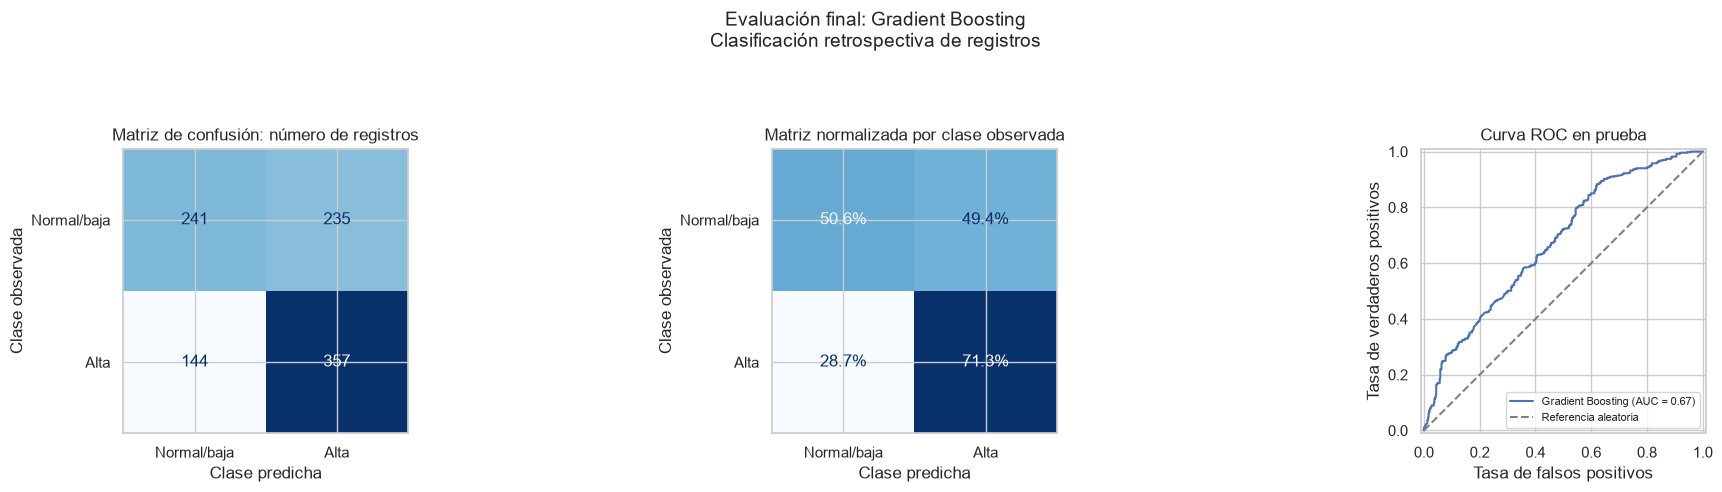


=== IMPORTANCIA POR PERMUTACIÓN EN VALIDACIÓN ===


,variable,disminucion_auc_media,desviacion
0,zona,0.1288,0.0136
1,lugar,0.0069,0.0024
2,area_hecho,0.0066,0.0051
3,mes_num,0.0049,0.0019
4,hora_num,0.0036,0.0015
5,etnia,0.0026,0.0009
6,nacionalidad,0.0021,0.0022
7,dia_semana,0.0021,0.0026
8,probable_causa_motivada,0.0017,0.0008
9,tipo_muerte,0.0014,0.0027


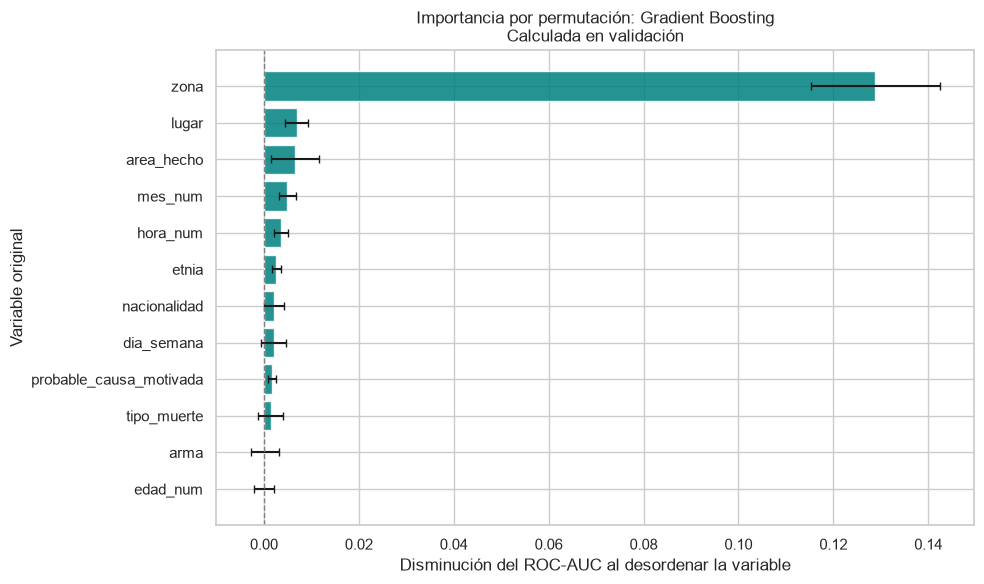


=== RESUMEN FINAL ===
Modelo seleccionado: Gradient Boosting
ROC-AUC en prueba: 0.6737
F1-Macro en prueba: 0.6065
Recall de alta concentración en prueba: 0.7126

Unidad evaluada: registros individuales de muertes, no subcircuitos agregados.
Separación territorial: los subcircuitos de prueba no participaron en entrenamiento ni en validación.
Alcance: clasificación retrospectiva según la concentración del periodo completo observado; no predicción de criticidad futura.
Las importancias describen el uso de variables por este modelo. No demuestran causalidad ni peligrosidad de grupos poblacionales.


In [ ]:
# BLOQUE 5: ASSESS
# Evaluación final e interpretación del modelo

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    balanced_accuracy_score
)
from sklearn.inspection import permutation_importance

# 1. Predicciones finales sobre prueba.
# No seleccionar modelos ni ajustar parámetros usando estos resultados.
y_pred = mejor_pipe.predict(X_test)

indice_positivo = list(mejor_pipe.classes_).index(1)
y_prob = mejor_pipe.predict_proba(X_test)[:, indice_positivo]

# 2. Métricas finales.
metricas_test = {
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "F1-Macro": f1_score(
        y_test,
        y_pred,
        average="macro",
        zero_division=0
    ),
    "Exactitud balanceada": balanced_accuracy_score(
        y_test,
        y_pred
    ),
    "Precisión clase 1": precision_score(
        y_test,
        y_pred,
        pos_label=1,
        zero_division=0
    ),
    "Recall clase 1": recall_score(
        y_test,
        y_pred,
        pos_label=1,
        zero_division=0
    )
}

tabla_metricas_test = pd.DataFrame(
    list(metricas_test.items()),
    columns=["metrica", "valor"]
)

print(f"\n=== EVALUACIÓN FINAL EN PRUEBA: {mejor_nombre} ===")
print(f"Registros evaluados: {len(y_test):,}")
print(f"Subcircuitos evaluados: {groups_test.nunique():,}")
print(
    "Porcentaje de registros de clase 1: "
    f"{100 * y_test.mean():.2f}%"
)

display(tabla_metricas_test.round(4))

print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=[
            "Concentración normal/baja",
            "Alta concentración"
        ],
        digits=4,
        zero_division=0
    )
)

# 3. Desglosar la matriz de confusión.
matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = matriz.ravel()

tabla_confusion = pd.DataFrame({
    "resultado": [
        "Verdaderos negativos",
        "Falsos positivos",
        "Falsos negativos",
        "Verdaderos positivos"
    ],
    "registros": [tn, fp, fn, tp]
})

print("\n=== DESGLOSE DE CLASIFICACIONES ===")
display(tabla_confusion)

# 4. Gráficos de evaluación final.
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Normal/baja", "Alta"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=axes[0]
)

axes[0].set_title("Matriz de confusión: número de registros")
axes[0].set_xlabel("Clase predicha")
axes[0].set_ylabel("Clase observada")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Normal/baja", "Alta"],
    normalize="true",
    cmap="Blues",
    colorbar=False,
    values_format=".1%",
    ax=axes[1]
)

axes[1].set_title("Matriz normalizada por clase observada")
axes[1].set_xlabel("Clase predicha")
axes[1].set_ylabel("Clase observada")

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=mejor_nombre,
    ax=axes[2]
)

axes[2].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Referencia aleatoria"
)

axes[2].set_title("Curva ROC en prueba")
axes[2].set_xlabel("Tasa de falsos positivos")
axes[2].set_ylabel("Tasa de verdaderos positivos")
axes[2].legend(loc="lower right", fontsize=8)

fig.suptitle(
    f"Evaluación final: {mejor_nombre}\n"
    "Clasificación retrospectiva de registros",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()

# 5. Importancia por permutación en validación.
# Se aplica al pipeline completo y a las variables originales.
# No reajusta el modelo.
print("\n=== IMPORTANCIA POR PERMUTACIÓN EN VALIDACIÓN ===")

perm = permutation_importance(
    estimator=mejor_pipe,
    X=X_val,
    y=y_val,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

tabla_importancias = (
    pd.DataFrame({
        "variable": X_val.columns,
        "disminucion_auc_media": perm.importances_mean,
        "desviacion": perm.importances_std
    })
    .sort_values(
        "disminucion_auc_media",
        ascending=False
    )
    .reset_index(drop=True)
)

display(tabla_importancias.round(4))

top_importancias = (
    tabla_importancias
    .head(12)
    .sort_values("disminucion_auc_media")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    top_importancias["variable"],
    top_importancias["disminucion_auc_media"],
    xerr=top_importancias["desviacion"],
    color="teal",
    alpha=0.85,
    capsize=3
)

ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    f"Importancia por permutación: {mejor_nombre}\n"
    "Calculada en validación"
)
ax.set_xlabel(
    "Disminución del ROC-AUC al desordenar la variable"
)
ax.set_ylabel("Variable original")

plt.tight_layout()
plt.show()

# 6. Resumen final y alcance.
print("\n=== RESUMEN FINAL ===")
print(f"Modelo seleccionado: {mejor_nombre}")
print(f"ROC-AUC en prueba: {metricas_test['ROC-AUC']:.4f}")
print(f"F1-Macro en prueba: {metricas_test['F1-Macro']:.4f}")
print(
    f"Recall de alta concentración en prueba: "
    f"{metricas_test['Recall clase 1']:.4f}"
)

print(
    "\nUnidad evaluada: registros individuales de muertes, "
    "no subcircuitos agregados."
)

print(
    "Separación territorial: los subcircuitos de prueba "
    "no participaron en entrenamiento ni en validación."
)

print(
    "Alcance: clasificación retrospectiva según la concentración "
    "del periodo completo observado; no predicción de criticidad futura."
)

print(
    "Las importancias describen el uso de variables por este modelo. "
    "No demuestran causalidad ni peligrosidad de grupos poblacionales."
)